In [11]:
using Flux
using Plots
using Chides
using TaylorSeries
pyplot();

In [12]:
function evalhinterp(x,ucof)

    deg_p1 = length(ucof) 
    u = zeros(size(x))
    z = ones(size(x))
    for d = 0:deg_p1-1
        u += ucof[1+d]*z
        z = z.*x
    end
    return u
    end ;

In [13]:
function scaletaylorkind!(u, Ul::Taylor1{Float64}, Ur::Taylor1{Float64}, m, h)
    # When using Taylor1 the factorial is built in
    df = 1.0
    for i = 1:m+1
        u[i,1] = df*Ul[i-1]
        u[i,2] = df*Ur[i-1]
        df *= h
    end
    end ;

In [5]:
# Hermite interpolation matrix
m = 15
Hmat = zeros(Float64,2*(m+1),2*(m+1))
xl = -1.0
xr = 1.0
xc = 0.0
icase = 0

hermitemap!(Hmat,m,xl,xr,xc,icase)

In [8]:
# Use a Taylor seris + AD to compute the
# interpolation data
affine(a) = a + Taylor1(typeof(a),2*m+3)

# 
tl = affine(xl)
tr = affine(xr)

idfun(x) = sin(11*x)

Ul = idfun(tl)
Ur = idfun(tr);


In [9]:
u = zeros(Float64,m+1,2)
h = xr-xl

scaletaylorkind!(u,Ul,Ur,m,h)
ucof = zeros(2*m+2)
ucof .= reshape(u,(2*m+2,1))[:]

neval = 1001

uint = Hmat*ucof

z = LinRange(-0.5,0.5,neval)
uplot = evalhinterp(z,uint)

x = LinRange(xl,xr,neval);

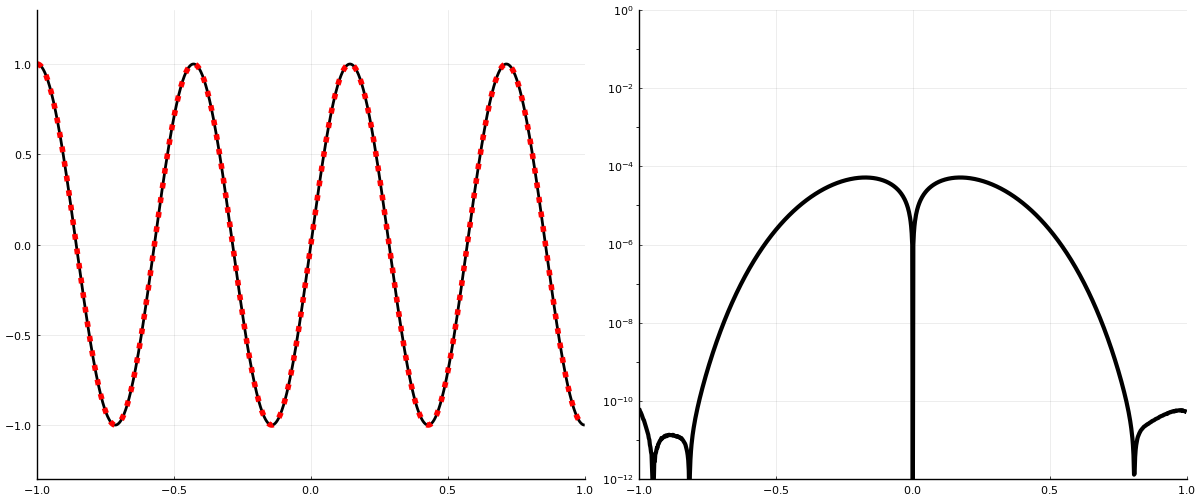

In [10]:
p1 = plot(x,uplot, lw = 2, color = [:black])
plot!(p1,x,idfun.(x), color = [:red],line = (:dot, 4),legend = false,
      xlims=(-1,1),ylims=(-1.3, 1.3))

p2 = plot(x,abs.(uplot-idfun.(x)),legend = false,yaxis=:log, lw = 3,
    color = [:black],xlims=(-1,1),ylims=(1e-12, 1.0))
plot(p1, p2, layout = (1,2), legend = false,size = (1200, 500))